<a href="https://colab.research.google.com/github/doanxuantuong/PlantLeafDiseaseClassification/blob/viet/Plant_Leaf_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q timm scikit-learn seaborn pandas matplotlib pillow tqdm

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
#Import, cấu hình và tái lập thực nghiệm ghi hết ở cell này
import os, random, time, json, hashlib, shutil, warnings
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_recall_fscore_support, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True
sns.set_style("whitegrid")

#tái lập thực nghiệm
SEED = 42
def seed_everything(s=SEED):
    random.seed(s);
    np.random.seed(s);
    torch.manual_seed(s);
    torch.cuda.manual_seed_all(s)
seed_everything()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("DÙng t4 GPT")

CFG = dict(
    IMG_SIZE=224,
    BATCH=64,
    EPOCHS=6,
    FREEZE_EPOCHS=1,      # Nếu ep == 0 thì đóng băng, đến ep == 1 thì mở toàn bộ
    PATIENCE=3,           # đếm số epoch ko cải thiện, đủ 3 thì dừng
    WD=0.0,
    NUM_WORKERS=2,
    MAX_PER_CLASS=None,   # đặt 100 để chạy thử nhanh; None = dùng toàn bộ dữ liệu
    OUTLIER_RATE=0.01,    # tỉ lệ ảnh bị đánh dấu bất thường trong mỗi lớp
    WORK_DIR="/content/work",
    DRIVE_OUT="/content/drive/MyDrive/N4k1/DataMining/datamining_plant_out",
)


# làm đẹp tên nhãn
def pretty(label):
    return label.replace("___", " - ").replace("_", " ")

# show nhiều ảnh
def show_grid(paths, titles, ncols=4, size=3):
    n = len(paths); nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, p, t in zip(axes, paths, titles):
        ax.imshow(Image.open(p).convert("RGB")); ax.set_title(t, fontsize=8)
    plt.tight_layout(); plt.show()

#tiền xử lí ảnh để đánh giá
def make_eval_tf(mean, std, size=None):
    size = size or CFG["IMG_SIZE"]
    return T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize(mean, std)])

# tự xây dựng dataset cho ảnh
# class ImgDS(Dataset):
#     def __init__(self, paths, labels, tf):
#         self.paths = list(paths); self.labels = list(labels); self.tf = tf
#     def __len__(self):
#         return len(self.paths)
#     def __getitem__(self, i):
#         img = Image.open(self.paths[i]).convert("RGB")
#         return self.tf(img), int(self.labels[i])

GPU: Tesla T4


In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print("Không ở môi trường Colab hoặc Drive đã được mount:", e)

SRC_DIR = "/content/drive/MyDrive/N4k1/DataMining/PlantVillage_Dataset"
OUT = Path(CFG["DRIVE_OUT"]);
OUT.mkdir(parents=True, exist_ok=True)
RAW = Path(CFG["WORK_DIR"]) / "raw";
RAW.mkdir(parents=True, exist_ok=True)

def extract_all(src, dst):
    for f in sorted(Path(src).iterdir()):
        print(f"- {f.name}  ({f.stat().st_size / 1e6:.1f} MB)" if f.is_file() else f"- {f.name}/ (thư mục)")
        if not f.is_file():
            continue
        out = dst / f.stem
        if out.exists():
            print("   đã giải nén trước đó, bỏ qua"); continue
        try:
            shutil.unpack_archive(str(f), str(out)); print("   giải nén ->", out)
        except (shutil.ReadError, ValueError):
            print("   không giải nén được (.rar/.7z cần: !apt-get -qq install unrar p7zip-full)")

extract_all(SRC_DIR, RAW)
for z in list(RAW.rglob("*.zip")):            # file zip lồng trong zip
    out = z.with_suffix("")
    if not out.exists():
        shutil.unpack_archive(str(z), str(out))

Mounted at /content/drive
- Plant_leaf_diseases_dataset_with_augmentation.zip  (949.3 MB)
   giải nén -> /content/work/raw/Plant_leaf_diseases_dataset_with_augmentation
- Plant_leaf_diseases_dataset_without_augmentation.zip  (868.0 MB)


In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
EXCLUDE_KW = ["__macosx"]    # nếu bộ dữ liệu có nhiều phiên bản ảnh, thêm "grayscale", "segmented" để chỉ dùng ảnh màu

def scan(root):
    rows = []
    for p in Path(root).rglob("*"):
        if (p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._")
                and not any(k in str(p).lower() for k in EXCLUDE_KW)):
            rows.append((str(p), p.parent.name))
    return pd.DataFrame(rows, columns=["path", "label"])

df = scan(RAW)
df["plant"] = df.label.str.split("___").str[0]
print("Tổng số ảnh:", len(df), "| Số lớp (theo tên thư mục):", df.label.nunique())
print("Số loài cây:", df.plant.nunique())
print(sorted(df.plant.unique()))

# Kiểm tra cấu trúc thư mục để chắc nhãn đúng
top = (df.path.str.replace(str(RAW) + "/", "", regex=False).str.split("/").str[:2].str.join("/"))
print(top.value_counts().head(15))
print("\nVí dụ nhãn:", sorted(df.label.unique())[:6])
if df.label.nunique() != 38:
    print("\n38 lớp nhưng tìm được", df.label.nunique())

Tổng số ảnh: 116934 | Số lớp (theo tên thư mục): 39
Số loài cây: 15
['Apple', 'Background_without_leaves', 'Blueberry', 'Cherry', 'Corn', 'Grape', 'Orange', 'Peach', 'Pepper,_bell', 'Potato', 'Raspberry', 'Soybean', 'Squash', 'Strawberry', 'Tomato']
path
Plant_leaf_diseases_dataset_with_augmentation/Plant_leave_diseases_dataset_with_augmentation          61486
Plant_leaf_diseases_dataset_without_augmentation/Plant_leave_diseases_dataset_without_augmentation    55448
Name: count, dtype: int64

Ví dụ nhãn: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Background_without_leaves', 'Blueberry___healthy']

38 lớp nhưng tìm được 39


# **Khai phá và tiền xử lý dữ liệu**

Nhiều nhất: Orange - Haunglongbing (Citrus greening) (11014) | Ít nhất: Potato - healthy (1152) | Tỉ lệ mất cân bằng: 9.6x
plant
Tomato                       10
Grape                         4
Apple                         4
Corn                          4
Potato                        3
Cherry                        2
Pepper,_bell                  2
Strawberry                    2
Peach                         2
Background_without_leaves     1
Blueberry                     1
Orange                        1
Raspberry                     1
Squash                        1
Soybean                       1

Ảnh lá khỏe mạnh: 33552 | ảnh lá bệnh: 83382


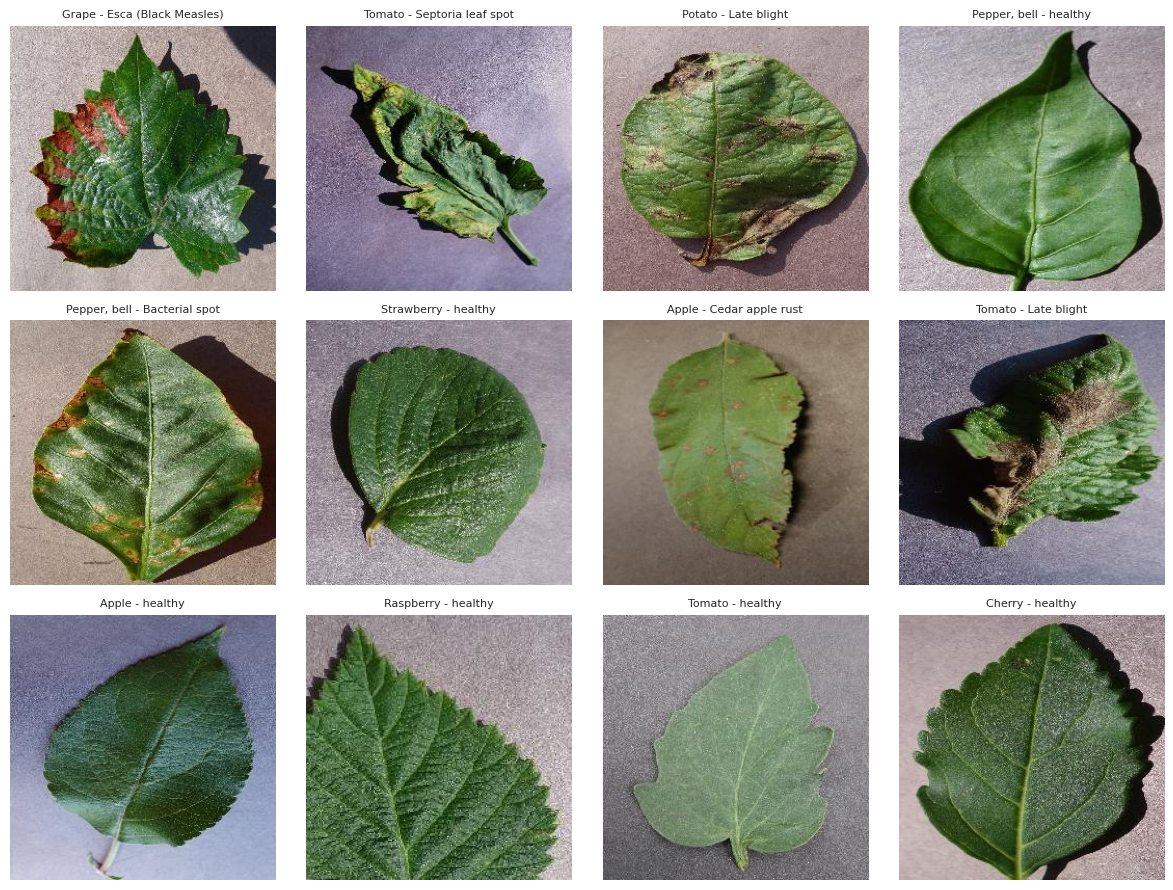

Kích thước ảnh phổ biến (mẫu 300 ảnh): [((256, 256), 283), ((204, 204), 9), ((256, 192), 6), ((350, 350), 2)]


In [ ]:
cnt = df.label.value_counts()
print(f"Nhiều nhất: {pretty(cnt.idxmax())} ({cnt.max()}) | Ít nhất: {pretty(cnt.idxmin())} ({cnt.min()}) "
      f"| Tỉ lệ mất cân bằng: {cnt.max() / cnt.min():.1f}x")

df["plant"] = df.label.str.split("___").str[0]
df["healthy"] = df.label.str.lower().str.contains("healthy")

print(df.groupby("plant").label.nunique().sort_values(ascending=False).to_string())
print(f"\nẢnh lá khỏe mạnh: {df.healthy.sum()} | ảnh lá bệnh: {(~df.healthy).sum()}")

rng = np.random.default_rng(SEED)
labs = rng.choice(sorted(df.label.unique()), size=min(12, df.label.nunique()), replace=False)
paths = [df[df.label == l].path.sample(1, random_state=SEED).iloc[0] for l in labs]
show_grid(paths, [pretty(l) for l in labs])

sizes = Counter(Image.open(p).size for p in df.path.sample(min(300, len(df)), random_state=SEED))
print("Kích thước ảnh phổ biến (mẫu 300 ảnh):", sizes.most_common(5))

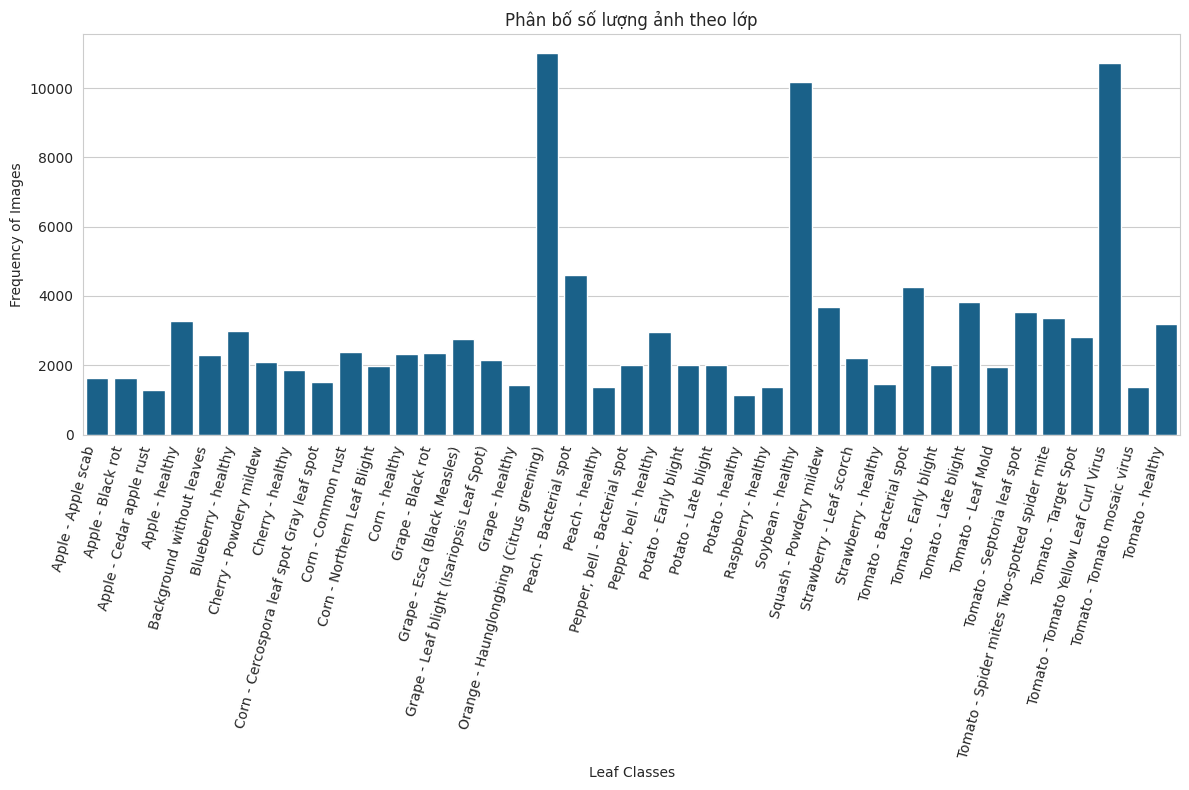

In [ ]:
class_stats = (df.groupby(["plant", "label"]).size().reset_index(name="count"))
class_stats["name"] = class_stats["label"].apply(pretty)
# Biểu đồ cột đứng theo lớp
plt.figure(figsize=(12, 8))

sns.barplot(data=class_stats.sort_values("name"),x="name",y="count",color="#08669B")

plt.title("Phân bố số lượng ảnh theo lớp")
plt.xlabel("Leaf Classes")
plt.ylabel("Frequency of Images")
plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.show()

Số lượng ảnh theo từng nguồn:
source
Plant_leaf_diseases_dataset_with_augmentation       61486
Plant_leaf_diseases_dataset_without_augmentation    55448
Name: count, dtype: int64


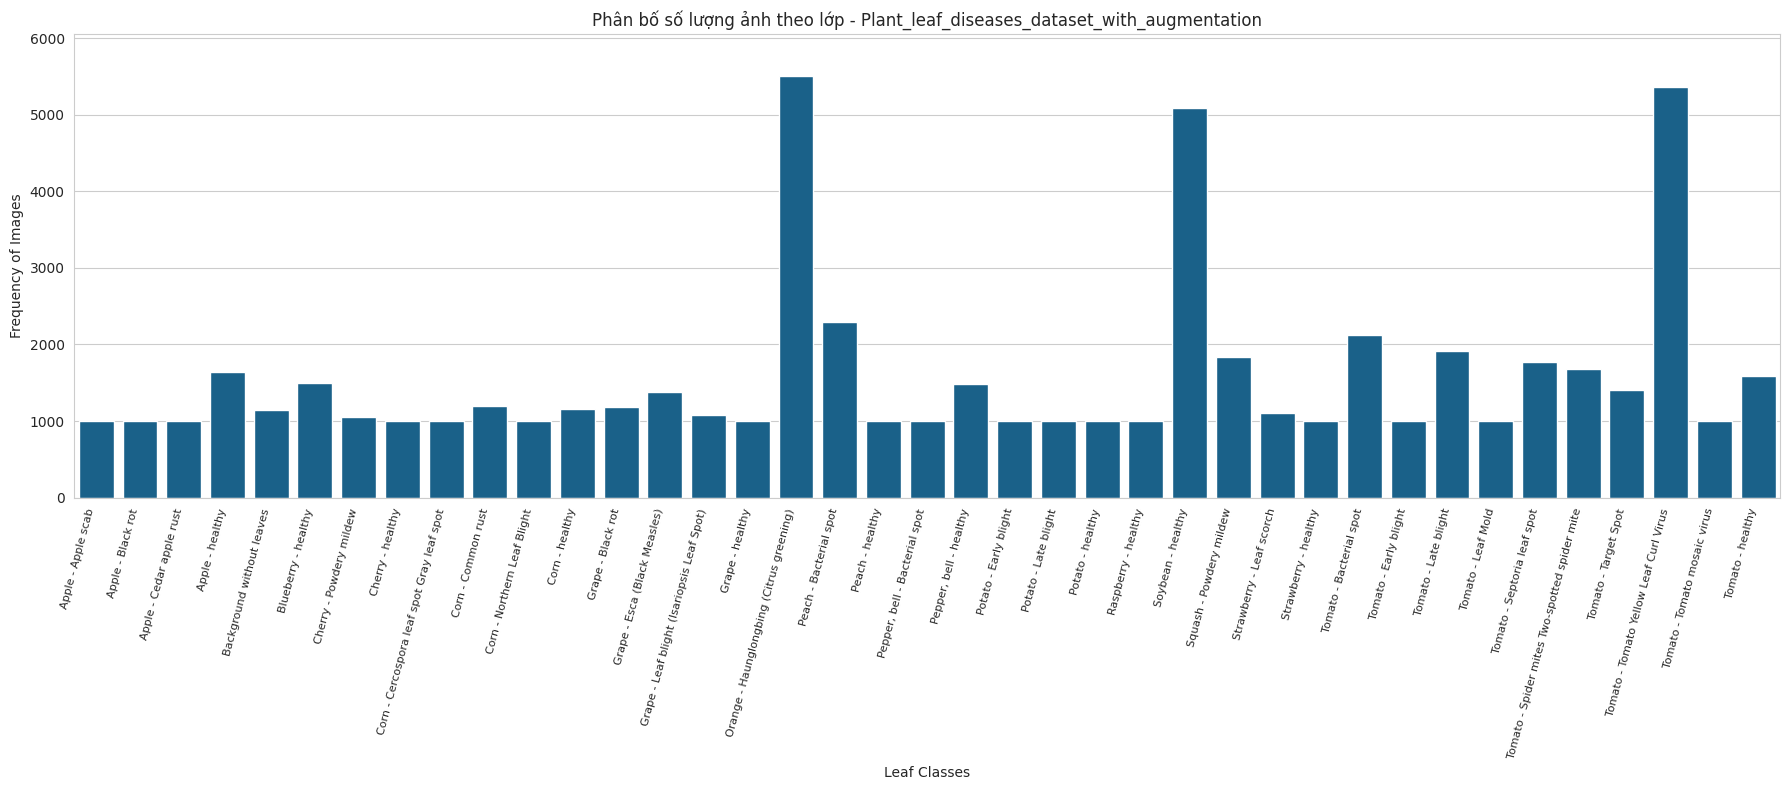

Tổng số ảnh: 61486


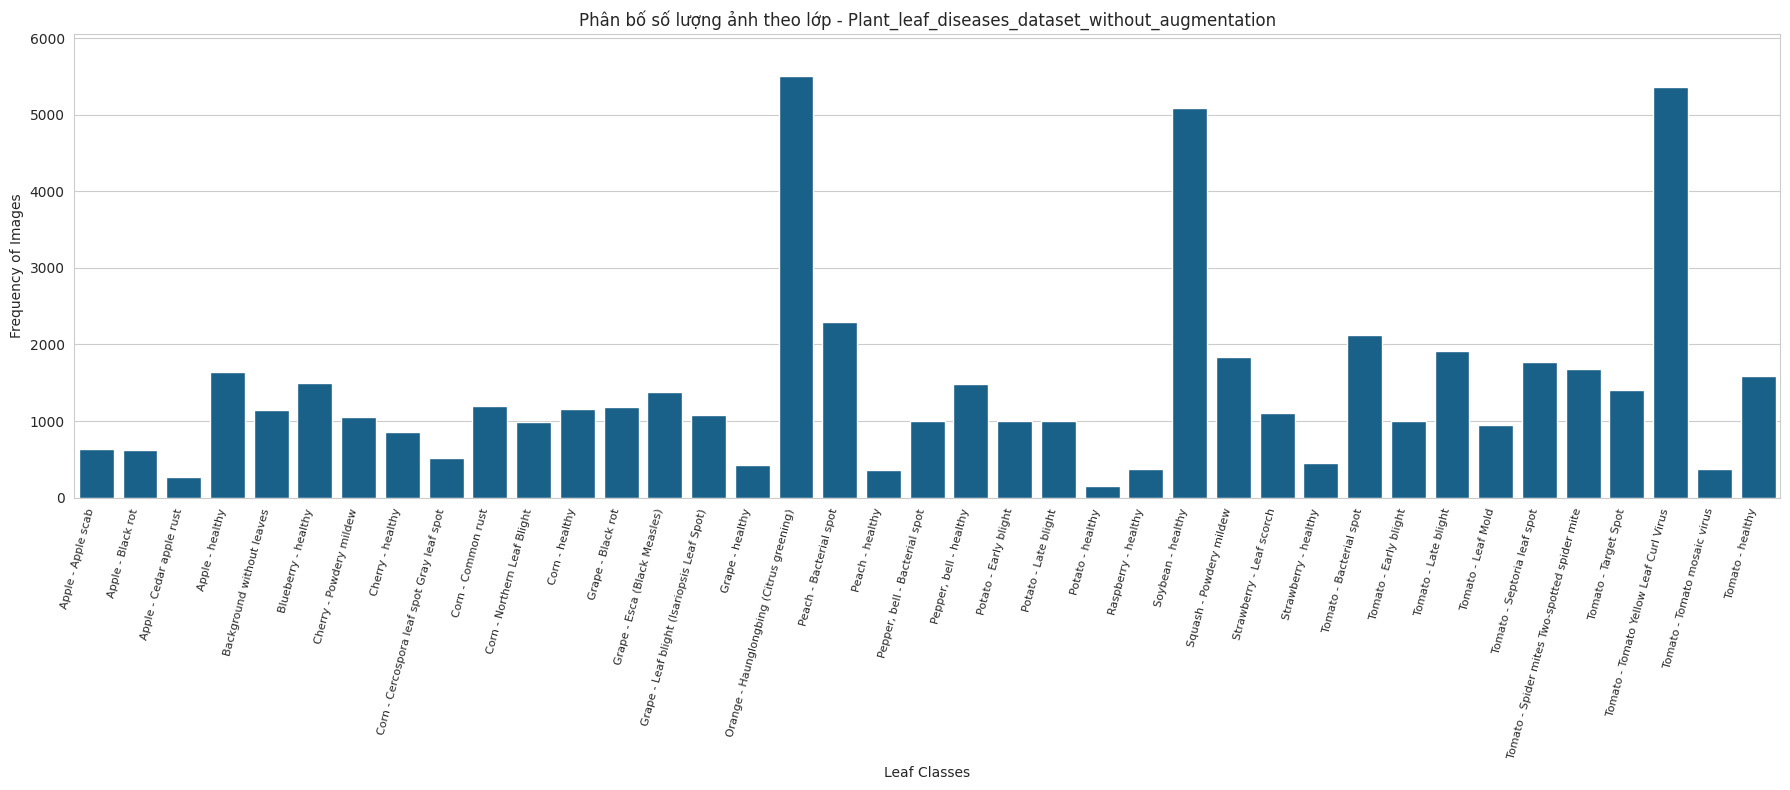

Tổng số ảnh: 55448


In [ ]:
# Xác định nguồn dữ liệu theo thư mục giải nén
df["source"] = df["path"].apply(
    lambda p: Path(p).relative_to(RAW).parts[0])

print("Số lượng ảnh theo từng nguồn:")
print(df["source"].value_counts())

# Giữ cùng thứ tự 38 lớp để dễ so sánh
class_order = sorted(df["label"].unique())
max_source_count = df.groupby(["source", "label"]).size().max()

# Vẽ biểu đồ cho từng nguồn dữ liệu
for source in sorted(df["source"].unique()):
    df_source = df[df["source"] == source]

    source_stats = (
        df_source["label"].value_counts().reindex(class_order, fill_value=0).rename_axis("label").reset_index(name="count"))

    source_stats["name"] = source_stats["label"].apply(pretty)

    plt.figure(figsize=(18, 8))

    sns.barplot(data=source_stats,x="name",y="count",color="#08669B")

    plt.title(f"Phân bố số lượng ảnh theo lớp - {source}")
    plt.xlabel("Leaf Classes")
    plt.ylabel("Frequency of Images")
    plt.xticks(rotation=75, ha="right", fontsize=8)
    plt.ylim(0, max_source_count * 1.1)

    plt.tight_layout()
    plt.show()

    print(f"Tổng số ảnh: {len(df_source)}")


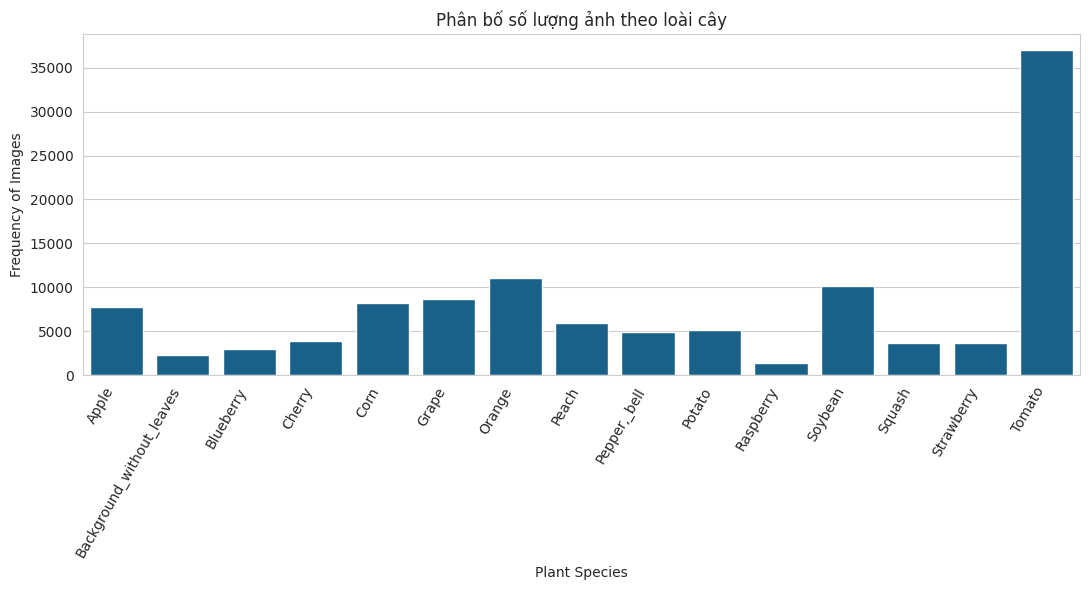

In [ ]:
# Biểu đồ cột đứng theo loài cây
plant_stats = (df.groupby("plant").size().reset_index(name="count").sort_values("plant"))

plt.figure(figsize=(11, 6))

sns.barplot(data=plant_stats,x="plant",y="count",color="#08669B")

plt.title("Phân bố số lượng ảnh theo loài cây")
plt.xlabel("Plant Species")
plt.ylabel("Frequency of Images")
plt.xticks(rotation=60, ha="right")

plt.tight_layout()
plt.show()